In [1]:
from pathlib import Path
import sys
import json
import hashlib
import platform
from datetime import datetime, timezone
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay,
)

SEMILLA = 42

# Funciona si el notebook se ejecuta desde la raíz del repo
# o desde aportes/juan.
actual = Path.cwd().resolve()
RAIZ = next(
    (
        carpeta
        for carpeta in [actual, *actual.parents]
        if (carpeta / "hotel_bookings.csv").is_file()
    ),
    None,
)

if RAIZ is None:
    raise FileNotFoundError(
        "No se encontró hotel_bookings.csv. "
        "Abre hotel-booking como carpeta del proyecto en VS Code."
    )

APORTE = RAIZ / "aportes" / "juan"
RESULTADOS = APORTE / "resultados"
RESULTADOS.mkdir(parents=True, exist_ok=True)

RUTA_DATOS = RAIZ / "hotel_bookings.csv"

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

print("Python:", sys.version.split()[0])
print("Ejecutable:", sys.executable)
print("Repositorio:", RAIZ)
print("Resultados:", RESULTADOS)

Python: 3.13.17
Ejecutable: c:\Especialización\hotel-booking\.venv\Scripts\python.exe
Repositorio: C:\Especialización\hotel-booking
Resultados: C:\Especialización\hotel-booking\aportes\juan\resultados


In [2]:
df_original = pd.read_csv(RUTA_DATOS, low_memory=False)

requeridas = {
    "hotel", "is_canceled", "lead_time",
    "arrival_date_year", "arrival_date_month",
    "arrival_date_day_of_month",
    "stays_in_weekend_nights", "stays_in_week_nights",
    "adults", "children", "babies", "adr",
    "meal", "country", "market_segment",
    "distribution_channel", "is_repeated_guest",
    "previous_cancellations", "previous_bookings_not_canceled",
    "reserved_room_type", "deposit_type", "customer_type",
}

faltantes = requeridas - set(df_original.columns)
if faltantes:
    raise ValueError(f"Faltan columnas necesarias: {sorted(faltantes)}")

if (
    df_original["is_canceled"].isna().any()
    or not df_original["is_canceled"].isin([0, 1]).all()
):
    raise ValueError("El objetivo is_canceled debe contener solamente 0 y 1.")

auditoria = pd.DataFrame({
    "variable": df_original.columns,
    "tipo": df_original.dtypes.astype(str).values,
    "nulos": df_original.isna().sum().values,
    "porcentaje_nulos": (
        df_original.isna().mean().values * 100
    ).round(2),
    "valores_distintos": df_original.nunique(dropna=True).values,
}).sort_values("porcentaje_nulos", ascending=False)

auditoria.to_csv(
    RESULTADOS / "auditoria_columnas.csv",
    index=False,
    encoding="utf-8-sig",
)

print("Filas y columnas:", df_original.shape)
print("Duplicados exactos:", df_original.duplicated().sum())
print(
    "Tasa de cancelación original:",
    f"{df_original['is_canceled'].mean():.2%}",
)

display(df_original.head())
display(auditoria)

Filas y columnas: (119390, 32)
Duplicados exactos: 31994
Tasa de cancelación original: 37.04%


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0000,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0000,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0000,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0000,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0000,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0000,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0000,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0000,NaN,0,Transient,75.0000,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0000,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0000,NaN,0,Transient,98.0000,0,1,Check-Out,2015-07-03


,variable,tipo,nulos,porcentaje_nulos,valores_distintos
24,company,float64,112593,94.3100,352
23,agent,float64,16340,13.6900,333
13,country,str,488,0.4100,177
0,hotel,str,0,0.0000,2
4,arrival_date_month,str,0,0.0000,12
5,arrival_date_week_number,int64,0,0.0000,53
2,lead_time,int64,0,0.0000,479
1,is_canceled,int64,0,0.0000,2
7,stays_in_weekend_nights,int64,0,0.0000,17
8,stays_in_week_nights,int64,0,0.0000,35


In [3]:
registro_limpieza = []

def registrar(paso, antes, despues, criterio):
    registro_limpieza.append({
        "paso": paso,
        "filas_antes": antes,
        "filas_despues": despues,
        "filas_eliminadas": antes - despues,
        "criterio": criterio,
    })

# Deduplicar antes de añadir identificadores auxiliares.
df = df_original.drop_duplicates().copy()

registrar(
    "Eliminar duplicados exactos",
    len(df_original),
    len(df),
    "Supuesto de trabajo; sin ID no se distingue duplicado de reserva idéntica.",
)

# El índice conserva la posición de la fila en el CSV original.
df["fila_csv"] = df.index + 2

# Conservamos huéspedes desconocidos; eliminamos únicamente cero conocido.
total_huespedes = df[["adults", "children", "babies"]].sum(
    axis=1,
    min_count=3,
)

antes = len(df)
df = df.loc[~total_huespedes.eq(0)].copy()

registrar(
    "Eliminar reservas con cero huéspedes conocidos",
    antes,
    len(df),
    "Suma adults + children + babies igual a cero.",
)

# Regla explícita tomada del diagnóstico del proyecto:
# ADR negativo o extremadamente alto pasa a nulo.
adr_invalido = (df["adr"] < 0) | (df["adr"] > 1000)
n_adr_invalidos = int(adr_invalido.sum())
df.loc[adr_invalido, "adr"] = np.nan

# Normalización fija, sin calcular estadísticas con test.
df["meal"] = df["meal"].replace({"Undefined": "SC"})

meses = {
    "January": 1, "February": 2, "March": 3,
    "April": 4, "May": 5, "June": 6,
    "July": 7, "August": 8, "September": 9,
    "October": 10, "November": 11, "December": 12,
}

df["fecha_llegada"] = pd.to_datetime(
    pd.DataFrame({
        "year": df["arrival_date_year"],
        "month": df["arrival_date_month"].map(meses),
        "day": df["arrival_date_day_of_month"],
    }),
    errors="coerce",
)

if df["fecha_llegada"].isna().any():
    raise ValueError(
        "Hay fechas de llegada inválidas. Revisarlas antes de dividir los datos."
    )

df["total_noches"] = (
    df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
)
df["mes_llegada"] = df["fecha_llegada"].dt.month.astype(str)
df["dia_semana_llegada"] = df["fecha_llegada"].dt.dayofweek.astype(str)

df = df.sort_values(
    ["fecha_llegada", "fila_csv"]
).reset_index(drop=True)

limpieza = pd.DataFrame(registro_limpieza)
limpieza.to_csv(
    RESULTADOS / "registro_limpieza.csv",
    index=False,
    encoding="utf-8-sig",
)

display(limpieza)
print("ADR convertidos a nulo:", n_adr_invalidos)
print("Filas disponibles:", len(df))
print("Cancelación después de limpieza:", f"{df['is_canceled'].mean():.2%}")

C:\Users\juanmj\AppData\Local\Temp\ipykernel_54952\4211499225.py:75: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["dia_semana_llegada"] = df["fecha_llegada"].dt.dayofweek.astype(str)


,paso,filas_antes,filas_despues,filas_eliminadas,criterio
0,Eliminar duplicados exactos,119390,87396,31994,Supuesto de trabajo; sin ID no se distingue du...
1,Eliminar reservas con cero huéspedes conocidos,87396,87230,166,Suma adults + children + babies igual a cero.


ADR convertidos a nulo: 2
Filas disponibles: 87230
Cancelación después de limpieza: 27.52%


In [4]:
numericas = [
    "lead_time",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "is_repeated_guest",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "adr",
]

categoricas = [
    "hotel",
    "meal",
    "country",
    "market_segment",
    "distribution_channel",
    "reserved_room_type",
    "deposit_type",
    "customer_type",
    "mes_llegada",
    "dia_semana_llegada",
]

variables = numericas + categoricas

# Exclusiones conservadoras para este experimento.
# Su disponibilidad real debe confirmarse con el dueño de los datos.
excluidas = [
    "reservation_status",
    "reservation_status_date",
    "assigned_room_type",
    "required_car_parking_spaces",
    "booking_changes",
    "days_in_waiting_list",
    "total_of_special_requests",
]

assert not set(variables).intersection(excluidas)

# Garantizar que las categóricas no mezclen números y texto.
for columna in categoricas:
    df[columna] = df[columna].map(
        lambda valor: str(valor) if pd.notna(valor) else np.nan
    )

train = df.loc[df["fecha_llegada"] < "2016-07-01"].copy()
valid = df.loc[
    (df["fecha_llegada"] >= "2016-07-01")
    & (df["fecha_llegada"] < "2017-01-01")
].copy()
test = df.loc[df["fecha_llegada"] >= "2017-01-01"].copy()

for nombre, parte in [
    ("train", train), ("validacion", valid), ("test", test)
]:
    if parte.empty or parte["is_canceled"].nunique() != 2:
        raise ValueError(f"{nombre} está vacío o no contiene ambas clases.")

assert train["fecha_llegada"].max() < valid["fecha_llegada"].min()
assert valid["fecha_llegada"].max() < test["fecha_llegada"].min()

X_train, y_train = train[variables], train["is_canceled"].astype(int)
X_valid, y_valid = valid[variables], valid["is_canceled"].astype(int)
X_test, y_test = test[variables], test["is_canceled"].astype(int)

particiones = pd.DataFrame([
    {
        "conjunto": nombre,
        "filas": len(parte),
        "desde": parte["fecha_llegada"].min().date().isoformat(),
        "hasta": parte["fecha_llegada"].max().date().isoformat(),
    }
    for nombre, parte in [
        ("train", train), ("validacion", valid), ("test", test)
    ]
])

particiones.to_csv(
    RESULTADOS / "particiones.csv",
    index=False,
    encoding="utf-8-sig",
)

# Permite que el equipo identifique exactamente qué filas se usaron.
asignacion = pd.concat([
    parte[["fila_csv", "fecha_llegada"]].assign(conjunto=nombre)
    for nombre, parte in [
        ("train", train), ("validacion", valid), ("test", test)
    ]
])

asignacion.to_csv(
    RESULTADOS / "asignacion_particiones.csv",
    index=False,
    encoding="utf-8-sig",
)

display(particiones)
print("Variables predictoras:", len(variables))

,conjunto,filas,desde,hasta
0,train,32817,2015-07-01,2016-06-30
1,validacion,22780,2016-07-01,2016-12-31
2,test,31633,2017-01-01,2017-08-31


Variables predictoras: 20


,hotel,reservas,canceladas,tasa_cancelacion
0,City Hotel,18607,4659,0.2504
1,Resort Hotel,14210,2622,0.1845


,market_segment,reservas,canceladas,tasa_cancelacion
6,Online TA,16587,4841,0.2919
5,Offline TA/TO,6805,915,0.1345
3,Direct,4665,605,0.1297
4,Groups,2332,645,0.2766
2,Corporate,2053,226,0.1101
1,Complementary,312,34,0.1090
0,Aviation,61,13,0.2131
7,Undefined,2,2,1.0000


,rango_anticipacion,reservas,canceladas,tasa_cancelacion
0,0–7,9011,752,0.0835
1,8–30,6738,1544,0.2291
2,31–90,9347,2672,0.2859
3,91–180,5458,1550,0.2840
4,>180,2263,763,0.3372


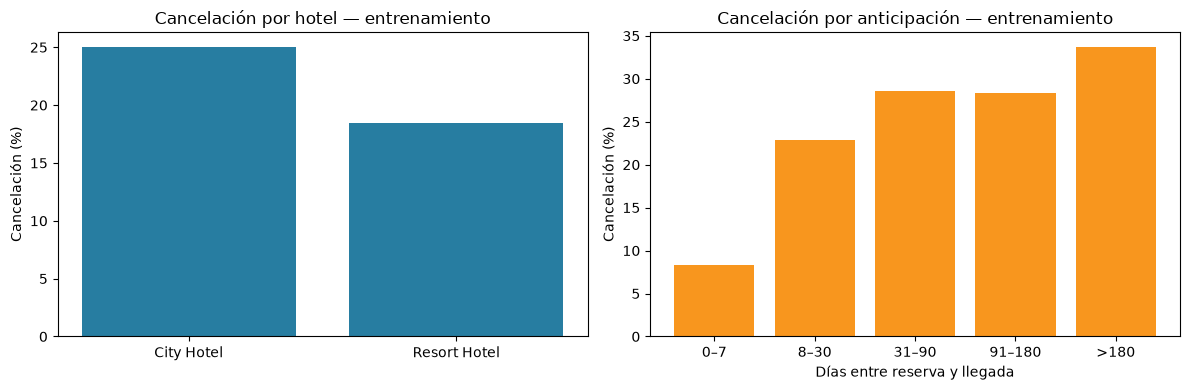

In [5]:
def resumen_grupo(datos, columna):
    tabla = (
        datos.groupby(columna, observed=True, dropna=False)["is_canceled"]
        .agg(reservas="size", canceladas="sum", tasa_cancelacion="mean")
        .reset_index()
    )
    return tabla.sort_values("reservas", ascending=False)

por_hotel = resumen_grupo(train, "hotel")
por_segmento = resumen_grupo(train, "market_segment")

eda = train.copy()
eda["rango_anticipacion"] = pd.cut(
    eda["lead_time"],
    bins=[-np.inf, 7, 30, 90, 180, np.inf],
    labels=["0–7", "8–30", "31–90", "91–180", ">180"],
)
por_anticipacion = resumen_grupo(
    eda, "rango_anticipacion"
).sort_values("rango_anticipacion")

for nombre, tabla in [
    ("eda_hotel_train", por_hotel),
    ("eda_segmento_train", por_segmento),
    ("eda_anticipacion_train", por_anticipacion),
]:
    tabla.to_csv(
        RESULTADOS / f"{nombre}.csv",
        index=False,
        encoding="utf-8-sig",
    )
    display(tabla)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(
    por_hotel["hotel"],
    por_hotel["tasa_cancelacion"] * 100,
    color="#277DA1",
)
axes[0].set_title("Cancelación por hotel — entrenamiento")
axes[0].set_ylabel("Cancelación (%)")

axes[1].bar(
    por_anticipacion["rango_anticipacion"].astype(str),
    por_anticipacion["tasa_cancelacion"] * 100,
    color="#F8961E",
)
axes[1].set_title("Cancelación por anticipación — entrenamiento")
axes[1].set_xlabel("Días entre reserva y llegada")
axes[1].set_ylabel("Cancelación (%)")

plt.tight_layout()
fig.savefig(RESULTADOS / "eda_train.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
preparacion_numerica = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),
    ("escalar", StandardScaler()),
])

preparacion_categorica = Pipeline([
    ("imputar", SimpleImputer(
        strategy="constant",
        fill_value="Desconocido",
    )),
    ("codificar", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=20,
        max_categories=50,
        sparse_output=True,
    )),
])

preprocesador = ColumnTransformer(
    transformers=[
        ("numericas", preparacion_numerica, numericas),
        ("categoricas", preparacion_categorica, categoricas),
    ],
    sparse_threshold=1.0,
)

candidatos = {
    "Referencia": DummyClassifier(strategy="prior"),
    "Regresion_logistica": LogisticRegression(
        max_iter=2000,
        random_state=SEMILLA,
    ),
    "Random_Forest": RandomForestClassifier(
        n_estimators=150,
        max_depth=14,
        min_samples_leaf=10,
        n_jobs=2,
        random_state=SEMILLA,
    ),
}

def calcular_metricas(y_real, probabilidades, umbral):
    predicciones = (np.asarray(probabilidades) >= umbral).astype(int)
    return {
        "roc_auc": float(roc_auc_score(y_real, probabilidades)),
        "average_precision": float(
            average_precision_score(y_real, probabilidades)
        ),
        "precision": float(precision_score(
            y_real, predicciones, zero_division=0
        )),
        "recall": float(recall_score(
            y_real, predicciones, zero_division=0
        )),
        "f1": float(f1_score(
            y_real, predicciones, zero_division=0
        )),
        "accuracy": float(accuracy_score(y_real, predicciones)),
        "porcentaje_alertas": float(predicciones.mean() * 100),
    }

modelos_entrenados = {}
resultados_validacion = []
umbrales_validacion = []

for nombre, estimador in candidatos.items():
    print(f"Entrenando: {nombre}...")

    modelo = Pipeline([
        ("preparacion", clone(preprocesador)),
        ("modelo", clone(estimador)),
    ])

    modelo.fit(X_train, y_train)
    probabilidades = modelo.predict_proba(X_valid)[:, 1]

    barrido = pd.DataFrame([
        {
            "umbral": float(t),
            "f1": f1_score(
                y_valid,
                probabilidades >= t,
                zero_division=0,
            ),
        }
        for t in np.linspace(0.01, 0.99, 99)
    ])

    # En empate se elige el umbral mayor: menos alertas.
    mejor_fila = barrido.sort_values(
        ["f1", "umbral"],
        ascending=[False, False],
    ).iloc[0]

    umbral = float(mejor_fila["umbral"])

    resultados_validacion.append({
        "modelo": nombre,
        "umbral": umbral,
        **calcular_metricas(y_valid, probabilidades, umbral),
    })

    umbrales_validacion.append(barrido.assign(modelo=nombre))
    modelos_entrenados[nombre] = modelo

comparacion = pd.DataFrame(resultados_validacion).sort_values(
    ["average_precision", "roc_auc"],
    ascending=False,
).reset_index(drop=True)

# Criterio fijado: mayor Average Precision en validación.
nombre_final = str(comparacion.iloc[0]["modelo"])
umbral_final = float(comparacion.iloc[0]["umbral"])
modelo_final = modelos_entrenados[nombre_final]

comparacion.to_csv(
    RESULTADOS / "comparacion_validacion.csv",
    index=False,
    encoding="utf-8-sig",
)

pd.concat(umbrales_validacion, ignore_index=True).to_csv(
    RESULTADOS / "umbrales_validacion.csv",
    index=False,
    encoding="utf-8-sig",
)

display(comparacion)
print("Modelo seleccionado:", nombre_final)
print("Umbral seleccionado:", round(umbral_final, 2))
print("Selección terminada. Ahora se evalúa el test.")

Entrenando: Referencia...
Entrenando: Regresion_logistica...
Entrenando: Random_Forest...


,modelo,umbral,roc_auc,average_precision,precision,recall,f1,accuracy,porcentaje_alertas
0,Random_Forest,0.2100,0.7493,0.5416,0.4527,0.7483,0.5641,0.6638,48.0509
1,Regresion_logistica,0.1400,0.7304,0.5268,0.4271,0.7458,0.5432,0.6353,50.7594
2,Referencia,0.2200,0.5000,0.2907,0.2907,1.0000,0.4504,0.2907,100.0000


Modelo seleccionado: Random_Forest
Umbral seleccionado: 0.21
Selección terminada. Ahora se evalúa el test.


,modelo,umbral,roc_auc,average_precision,precision,recall,f1,accuracy,porcentaje_alertas
0,Random_Forest,0.2100,0.7455,0.5697,0.4657,0.7789,0.5829,0.6439,53.4315


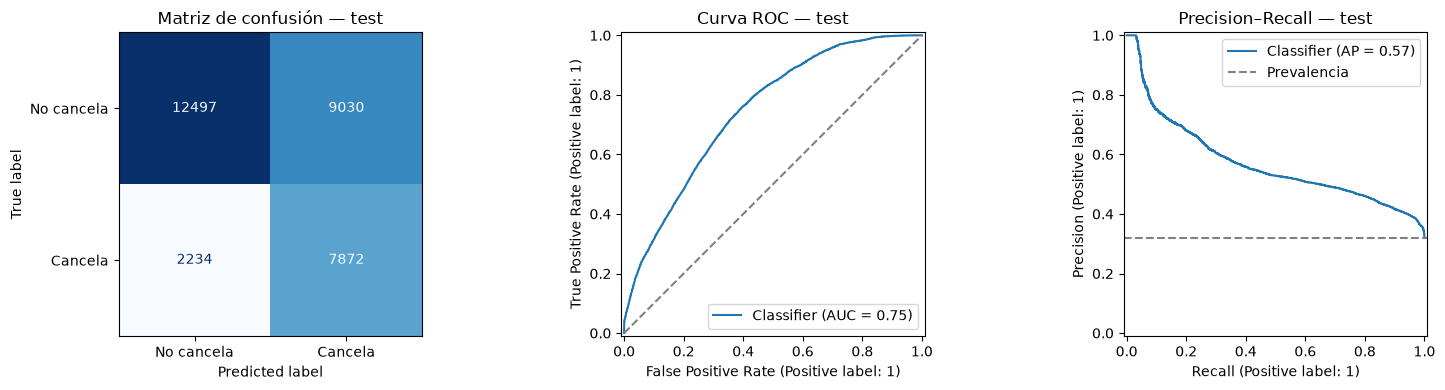

,decil_riesgo,reservas,canceladas,tasa_cancelacion,lift,fraccion_cancelaciones_capturadas
0,1,3164,2135,0.6748,2.1121,0.2113
1,2,3163,1499,0.4739,1.4834,0.1483
2,3,3163,1388,0.4388,1.3736,0.1373
3,4,3163,1343,0.4246,1.3290,0.1329
4,5,3164,1174,0.3710,1.1614,0.1162
5,6,3163,910,0.2877,0.9005,0.0900
6,7,3163,719,0.2273,0.7115,0.0711
7,8,3163,615,0.1944,0.6086,0.0609
8,9,3163,265,0.0838,0.2622,0.0262
9,10,3164,58,0.0183,0.0574,0.0057


Decil 1 = 10 % de reservas con mayor riesgo predicho.


In [7]:
# Se conserva el modelo entrenado previamente:
# no se vuelve a entrenar después de elegir el umbral.
prob_test = modelo_final.predict_proba(X_test)[:, 1]
pred_test = (prob_test >= umbral_final).astype(int)

metricas_test = calcular_metricas(
    y_test,
    prob_test,
    umbral_final,
)

resultado_test = pd.DataFrame([{
    "modelo": nombre_final,
    "umbral": umbral_final,
    **metricas_test,
}])

resultado_test.to_csv(
    RESULTADOS / "evaluacion_test.csv",
    index=False,
    encoding="utf-8-sig",
)

display(resultado_test)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_test,
    labels=[0, 1],
    display_labels=["No cancela", "Cancela"],
    cmap="Blues",
    colorbar=False,
    ax=axes[0],
)
axes[0].set_title("Matriz de confusión — test")

RocCurveDisplay.from_predictions(
    y_test,
    prob_test,
    ax=axes[1],
)
axes[1].plot([0, 1], [0, 1], "--", color="gray")
axes[1].set_title("Curva ROC — test")

PrecisionRecallDisplay.from_predictions(
    y_test,
    prob_test,
    ax=axes[2],
)
axes[2].axhline(
    y_test.mean(),
    linestyle="--",
    color="gray",
    label="Prevalencia",
)
axes[2].legend()
axes[2].set_title("Precision–Recall — test")

plt.tight_layout()
fig.savefig(
    RESULTADOS / "evaluacion_test.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

# Ranking para analizar concentración del riesgo.
ranking = pd.DataFrame({
    "fila_csv": test["fila_csv"].to_numpy(),
    "fecha_llegada": test["fecha_llegada"].to_numpy(),
    "hotel": test["hotel"].to_numpy(),
    "real": y_test.to_numpy(),
    "probabilidad_cancelacion": prob_test,
    "alerta": pred_test,
}).sort_values(
    ["probabilidad_cancelacion", "fila_csv"],
    ascending=[False, True],
).reset_index(drop=True)

ranking["decil_riesgo"] = pd.qcut(
    ranking.index,
    q=10,
    labels=range(1, 11),
).astype(int)

deciles = (
    ranking.groupby("decil_riesgo")
    .agg(
        reservas=("real", "size"),
        canceladas=("real", "sum"),
        tasa_cancelacion=("real", "mean"),
    )
    .reset_index()
)

deciles["lift"] = deciles["tasa_cancelacion"] / y_test.mean()
deciles["fraccion_cancelaciones_capturadas"] = (
    deciles["canceladas"] / y_test.sum()
)

ranking.to_csv(
    RESULTADOS / "predicciones_test.csv",
    index=False,
    encoding="utf-8-sig",
)
deciles.to_csv(
    RESULTADOS / "deciles_test.csv",
    index=False,
    encoding="utf-8-sig",
)

display(deciles)
print("Decil 1 = 10 % de reservas con mayor riesgo predicho.")

In [8]:
versiones = {
    paquete: version(paquete)
    for paquete in ["pandas", "numpy", "scikit-learn", "matplotlib"]
}

sha_datos = hashlib.sha256(RUTA_DATOS.read_bytes()).hexdigest()

metadata = {
    "autor": "Juan",
    "ejecutado_utc": datetime.now(timezone.utc).isoformat(),
    "python": platform.python_version(),
    "versiones": versiones,
    "sha256_csv_original": sha_datos,
    "semilla": SEMILLA,
    "filas_originales": len(df_original),
    "filas_limpias": len(df),
    "adr_convertidos_a_nulo": n_adr_invalidos,
    "variables": variables,
    "exclusiones_conservadoras": excluidas,
    "modelo_seleccionado": nombre_final,
    "criterio_modelo": "Mayor Average Precision en validación",
    "criterio_umbral": "Máximo F1 en validación",
    "umbral": umbral_final,
    "metricas_test": metricas_test,
    "particiones": particiones.to_dict(orient="records"),
}

(RESULTADOS / "metadata_juan.json").write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

(APORTE / "requirements_juan.txt").write_text(
    "\n".join(
        f"{paquete}=={numero}"
        for paquete, numero in versiones.items()
    ) + "\n",
    encoding="utf-8",
)

tn, fp, fn, tp = confusion_matrix(
    y_test, pred_test, labels=[0, 1]
).ravel()

informe = f"""# Resultados del aporte de Juan

## Pregunta
¿Con qué desempeño se pueden ordenar reservas por riesgo de cancelación
al evaluar en un periodo posterior al entrenamiento?

## Preparación
- Registros originales: {len(df_original):,}.
- Registros después de limpieza: {len(df):,}.
- ADR convertidos a nulo: {n_adr_invalidos}.
- Huella SHA-256 del CSV: `{sha_datos}`.

## Protocolo
- Entrenamiento: llegadas anteriores a julio de 2016.
- Validación: llegadas de julio a diciembre de 2016.
- Test: llegadas desde enero de 2017.
- Imputación y codificación ajustadas solamente en entrenamiento.
- Modelo elegido por Average Precision en validación.
- Umbral elegido por máximo F1 en validación.
- Modelo y umbral congelados antes de evaluar test.
- No se reentrena el modelo después de seleccionar el umbral.

## Resultado en test
- Modelo: {nombre_final}.
- Umbral: {umbral_final:.2f}.
- ROC-AUC: {metricas_test['roc_auc']:.4f}.
- Average Precision: {metricas_test['average_precision']:.4f}.
- Precision: {metricas_test['precision']:.2%}.
- Recall: {metricas_test['recall']:.2%}.
- F1: {metricas_test['f1']:.4f}.
- Prevalencia del test: {y_test.mean():.2%}.
- Verdaderos positivos: {tp:,}.
- Falsos positivos: {fp:,}.
- Falsos negativos: {fn:,}.
- Verdaderos negativos: {tn:,}.

## Interpretación
Al umbral seleccionado, el modelo identifica {tp:,} cancelaciones
y genera {fp:,} alertas en reservas que no cancelaron.
Quedan {fn:,} cancelaciones sin detectar.

El umbral maximiza F1 en validación; no representa un óptimo económico.
Para decidir su uso se necesitan los costos de intervenir y de no detectar
una cancelación.

Average Precision resume el desempeño precision-recall;
no se presenta como área trapezoidal bajo esa curva.

## Limitaciones
- Los duplicados exactos podrían representar reservas legítimas idénticas.
- La evaluación se hace sobre datos deduplicados y no representa
  necesariamente la prevalencia operacional.
- La partición usa fecha de llegada, no fecha de emisión de la predicción.
- No se reconstruye cuándo se conoció el resultado de cada reserva.
- Faltan versiones históricas de las variables al momento de reservar.
- Las exclusiones reducen riesgos, pero no prueban ausencia total de fuga.
- Las asociaciones encontradas no demuestran causalidad.
- Se utiliza una sola ventana de validación y una sola ventana de test.
- No se midieron intervalos de confianza.
- El rendimiento corresponde a dos hoteles y al periodo del dataset.

## Comparación con el trabajo del equipo
No comparar directamente este resultado con el AUC de un test aleatorio.
Para una comparación controlada, entrenar ambos enfoques con las mismas
filas y el mismo protocolo, usando asignacion_particiones.csv.

El modelo guardado originalmente por el equipo no debe evaluarse como
independiente sobre estas filas si pudo entrenarse con ellas.

Acordar también el tratamiento de duplicados, el momento de predicción
y las métricas antes de concluir que un enfoque es superior.
"""

(RESULTADOS / "informe_resultados.md").write_text(
    informe,
    encoding="utf-8",
)

readme = """# Aporte de Juan — Proyecto I

## Contenido
- Proyecto_Juan.ipynb: auditoría, limpieza, EDA y modelado.
- requirements_juan.txt: versiones utilizadas en esta ejecución.
- resultados/: tablas, gráficos, predicciones e informe generado.

## Ejecución
1. Abrir el repositorio hotel-booking en VS Code.
2. Seleccionar un entorno Python con las dependencias instaladas.
3. Abrir aportes/juan/Proyecto_Juan.ipynb.
4. Ejecutar las celdas en orden.
5. Leer resultados/informe_resultados.md.

Se utiliza hotel_bookings.csv de la raíz del repositorio.
Las salidas se escriben únicamente en aportes/juan.
Cada ejecución reemplaza los resultados anteriores de este aporte.

## Aporte metodológico
Se separan entrenamiento, validación y test por fecha de llegada.
La selección del modelo y del umbral se realiza con validación.
El test se usa después de congelar esas decisiones.

## Revisión del equipo
Revisar las reglas de limpieza, exclusiones, particiones y conclusiones.
Para comparar modelos, usar las mismas filas de evaluación y evitar
evaluar como independiente un modelo que ya entrenó con esas filas.

## Autoría y herramientas
Autor: Juan.
Código preparado con asistencia de ChatGPT.
Juan y el equipo deben revisar la ejecución e interpretar sus resultados.
"""

(APORTE / "README.md").write_text(readme, encoding="utf-8")

print("Documentación generada.")
print(informe)
print("\nArchivos de resultados:")
for archivo in sorted(RESULTADOS.iterdir()):
    if archivo.is_file():
        print("-", archivo.name)

Documentación generada.
# Resultados del aporte de Juan

## Pregunta
¿Con qué desempeño se pueden ordenar reservas por riesgo de cancelación
al evaluar en un periodo posterior al entrenamiento?

## Preparación
- Registros originales: 119,390.
- Registros después de limpieza: 87,230.
- ADR convertidos a nulo: 2.
- Huella SHA-256 del CSV: `d10cdeb07de9309007f528d6499a2c0467ae7a6b287b80ffd759e11e61801639`.

## Protocolo
- Entrenamiento: llegadas anteriores a julio de 2016.
- Validación: llegadas de julio a diciembre de 2016.
- Test: llegadas desde enero de 2017.
- Imputación y codificación ajustadas solamente en entrenamiento.
- Modelo elegido por Average Precision en validación.
- Umbral elegido por máximo F1 en validación.
- Modelo y umbral congelados antes de evaluar test.
- No se reentrena el modelo después de seleccionar el umbral.

## Resultado en test
- Modelo: Random_Forest.
- Umbral: 0.21.
- ROC-AUC: 0.7455.
- Average Precision: 0.5697.
- Precision: 46.57%.
- Recall: 77.89%.
- F1